In [1]:
# Import necessary libraries for data analysis and genome-scale metabolic modeling
import pandas as pd  # For data manipulation and CSV file handling
import cobra  # COBRApy for genome-scale metabolic model analysis
# Import flux analysis methods for gene/reaction deletion studies
from cobra.flux_analysis import (
    single_gene_deletion)

In [2]:
# Load experimental essential genes data from CSV file
essential_df = pd.read_csv("essentialGenes.csv", sep='\t', header=None)
# Extract essential gene names (column 1) into a set for fast lookup
essential_genes = set(essential_df[1])

In [3]:
# Load UniProtKB mapping file containing gene names and RefSeq identifiers
formap = pd.read_csv("uniprotkb_taxonomy_id_559292_2025_08_19.tsv", sep="\t")

# Remove rows with missing gene names to ensure data quality
formap = formap.dropna(subset=["Gene Names (ordered locus)"])

In [4]:
# Build a mapping dictionary of RefSeq IDs to gene names for essential genes
selGenes = {}  # Dictionary: RefSeq ID -> gene name
for k, essential in essential_df.iterrows():    
    print(essential[1])  # Print gene name for progress tracking
    # Find matching genes in the UniProtKB mapping file
    sel = formap[formap["Gene Names (ordered locus)"].str.contains(essential[1])]
    print(sel.iloc[0]["RefSeq"])  # Print RefSeq ID for verification
    try:
        # Process RefSeq IDs (can be semicolon-separated)
        for gen in sel.iloc[0]["RefSeq"].split(";"):
            if len(gen) < 3:  # Skip very short identifiers
                continue
            # Remove organism information in square brackets
            if " [" in gen:
                gen = gen.split(" [")[0]

            # Keep only the base ID (before the dot version number)        pass

            gen = gen.split(".")[0]   
            selGenes[gen] = essential[1]  # Map RefSeq ID to gene name
    except:  # Do nothing where gene mapping fails
        pass

YAL001C
NP_009400.1;
YAL003W
NP_009398.1;
YAL025C
NP_009377.2;
YAL032C
NP_009370.1;
YAL033W
NP_009369.1;
YAL034W-A
NP_009367.1;
YAL038W
NP_009362.1;
YAL041W
NP_009359.1;
YAL043C
NP_009356.1;
YAR007C
NP_009404.1;
YAR008W
NP_009405.1;
YAR019C
NP_009411.2;
YBL003C
NP_009552.1;
YBL004W
NP_009551.2;
YBL014C
NP_009539.2;
YBL018C
NP_009535.1;
YBL020W
NP_009533.1;
YBL023C
NP_009530.1;
YBL026W
NP_009527.1;
YBL030C
NP_009523.1;
YBL034C
NP_009519.1;
YBL035C
NP_009518.1;
YBL040C
NP_009513.1;
YBL041W
NP_009512.1;
YBL050W
NP_009503.1;
YBL074C
NP_009479.1;
YBL076C
NP_009477.1;
YBL084C
NP_009469.2;
YBL092W
NP_009460.1;
YBL097W
NP_009455.3;
YBL102W
NP_009448.1;
YBL105C
NP_009445.2;
YBR002C
NP_009556.1;
YBR004C
NP_009558.2;
YBR009C
NP_009563.1;NP_014368.1;
YBR011C
NP_009565.1;
YBR024W
NP_009580.1;
YBR029C
NP_009585.1;
YBR038W
NP_009594.1;
YBR049C
NP_009605.1;
YBR055C
NP_009611.1;
YBR060C
NP_009616.1;
YBR070C
NP_009626.1;
YBR079C
NP_009635.1;
YBR080C
NP_009636.3;
YBR087W
NP_009644.3;
YBR088C
NP_009645.1;

In [5]:
# Load the first CarveFungi yeast model (GEM: Genome-scale Metabolic Model)
model = cobra.io.read_sbml_model("../results/Saccharomyces cerevisiae--839.6428285154577-971.6627611556756.sbml")
# Set nutrient exchange reaction to allow sufficient nutrient uptake
model.reactions.UF02997_E.lower_bound = -1000

# Perform in silico single gene deletion analysis to identify essential genes
deletion_results = single_gene_deletion(model)
# Filter for genes whose deletion results in zero growth (essential genes)
deletions_essential = deletion_results[deletion_results["growth"] == 0]
# Extract list of predicted essential gene IDs
predicted_essential = []
for k, r in deletions_essential.iterrows():
    predicted_essential.append(str(list(r["ids"])[0])) 

# Collect all gene IDs in the model for comprehensive analysis
all_genes = []
for gene in model.genes:
    all_genes.append(gene.id)

In [19]:
modelActSeek= cobra.io.read_sbml_model("../results/Saccharomyces cerevisiae_ActSeekN--2459.900716071449-2881.031673918169.sbml")
modelActSeek.reactions.UF02997_E.lower_bound=-1000
deletion_results_actseek = single_gene_deletion(modelActSeek)
deletions_essential_actseek = deletion_results_actseek[deletion_results_actseek["growth"]==0]
predicted_essential_actseek=[]
for k, r in deletions_essential_actseek.iterrows():
    predicted_essential_actseek.append(str(list(r["ids"])[0]))
    
all_genes_actseek = []
for gene in modelActSeek.genes:
    all_genes_actseek.append(gene.id)

In [20]:
consensus_yeast_model= cobra.io.read_sbml_model("yeast-GEM.xml")
deletion_results = single_gene_deletion(consensus_yeast_model)
deletions_essential_consensus_yeast = deletion_results[deletion_results["growth"]==0]
predicted_essential_consensus_yeast=[]
for k, r in deletions_essential_consensus_yeast.iterrows():
    predicted_essential_consensus_yeast.append(str(list(r["ids"])[0]))
    
all_genes_consensus_yeast = []
for gene in consensus_yeast_model.genes:
    all_genes_consensus_yeast.append(gene.id)

In [8]:
y_true = []
y_pred = []
for gene in all_genes:
    if gene.split(".")[0] in selGenes:
        print(gene, selGenes[gene.split(".")[0]])
    if gene.split(".")[0] in selGenes and selGenes[gene.split(".")[0]] in essential_genes:
        y_true.append("N")
    else:
        y_true.append("V")
    if gene in predicted_essential:
        y_pred.append("N")
    else:
        y_pred.append("V")

NP_010239.1 YDL045C
NP_013463.1 YLR359W
NP_015208.1 YPL117C
NP_011783.1 YGR267C
NP_009477.1 YBL076C
NP_009362.1 YAL038W
NP_009711.3 YBR153W
NP_014819.3 YOR176W
NP_116637.1 YFL017C
NP_009755.1 YBR196C
NP_015360.2 YPR035W
NP_014738.1 YOR095C
NP_014413.1 YNR016C
NP_010494.1 YDR208W
NP_014717.2 YOR074C
NP_012739.1 YKL182W
NP_010076.1 YDL205C
NP_012863.1 YKL060C
NP_013161.1 YLR060W
NP_010322.1 YDR037W
NP_013935.1 YMR208W
NP_014786.1 YOR143C
NP_011883.1 YHR019C
NP_010329.1 YDR044W
NP_010482.3 YDR196C
NP_010332.3 YDR047W
NP_011941.1 YHR074W
NP_009679.2 YBR121C
NP_009565.1 YBR011C
NP_012368.1 YJL167W
NP_011780.3 YGR264C
NP_012835.1 YKL088W
NP_013831.1 YMR113W
NP_013408.1 YLR305C
NP_009811.3 YBR252W
NP_010640.1 YDR353W
NP_014544.1 YOL097C
NP_010820.3 YDR531W
NP_010856.1 YEL058W
NP_014980.3 YOR335C
NP_012818.1 YKL104C
NP_014879.1 YOR236W
NP_010742.1 YDR454C
NP_009815.1 YBR256C
NP_012901.3 YKL024C
NP_010522.1 YDR236C
NP_011760.3 YGR244C
NP_009585.1 YBR029C
NP_009923.2 YCL004W
NP_011507.1 YGL008C


In [9]:
y_true_actseek = []
y_pred_actseek = []
for gene in all_genes_actseek:
    print(gene)
    if gene.split(".")[0] in selGenes:
        print(gene, selGenes[gene.split(".")[0]])
    if gene.split(".")[0] in selGenes and selGenes[gene.split(".")[0]] in essential_genes:
        y_true_actseek.append("N")
    else:
        y_true_actseek.append("V")
    if gene in predicted_essential_actseek:
        y_pred_actseek.append("N")
    else:
        y_pred_actseek.append("V")

NP_015302.1
NP_011390.2
NP_009755.1
NP_009755.1 YBR196C
NP_012816.1
NP_013127.2
NP_012150.1
NP_011079.3
NP_009703.3
NP_015055.1
NP_014763.1
NP_010656.1
NP_009578.1
NP_013805.1
NP_011898.1
NP_010586.3
NP_014884.1
NP_013677.1
NP_015093.1
NP_015093.1 YPL231W
NP_013481.3
NP_013359.1
NP_116670.1
NP_009912.2
NP_009912.2 YCL017C
NP_012612.3
NP_010482.3
NP_010482.3 YDR196C
NP_010302.1
NP_009808.1
NP_010320.3
NP_011718.1
NP_013710.1
NP_009593.1
NP_009580.1
NP_009580.1 YBR024W
NP_014554.1
NP_009999.2
NP_014432.3
NP_011764.3
NP_012033.2
NP_015230.1
NP_009736.3
NP_116686.3
NP_116579.1
NP_014051.3
NP_010030.1
NP_009890.1
NP_010804.3
NP_013601.1
NP_013998.1
NP_010522.1
NP_010522.1 YDR236C
NP_010960.1
NP_014064.1
NP_116594.1
NP_012667.1
NP_010687.3
NP_011795.1
NP_011487.3
NP_014035.1
NP_014717.2
NP_014717.2 YOR074C
NP_014328.3
NP_014270.1
NP_015326.1
NP_011793.3
NP_011793.3 YGR277C
NP_015212.1
NP_014125.1
NP_014150.1
NP_010542.1
NP_011602.2
NP_009807.3
NP_009409.1
NP_010534.1
NP_013953.1
NP_009318.1


In [21]:
y_true_yeast = []
y_pred_yeast = []
for gene in all_genes_consensus_yeast:
    print(gene)    
    if gene in essential_genes:
        y_true_yeast.append("N")
    else:
        y_true_yeast.append("V")
    if gene in predicted_essential_consensus_yeast:
        y_pred_yeast.append("N")
    else:
        y_pred_yeast.append("V")

Q0045
Q0080
Q0085
Q0105
Q0130
Q0250
Q0275
YAL012W
YAL022C
YAL023C
YAL026C
YAL035W
YAL038W
YAL039C
YAL044C
YAL054C
YAL060W
YAL061W
YAL062W
YAR015W
YAR035W
YAR071W
YBL011W
YBL013W
YBL015W
YBL030C
YBL033C
YBL039C
YBL042C
YBL045C
YBL064C
YBL068W
YBL076C
YBL080C
YBL091C
YBL098W
YBL099W
YBR001C
YBR002C
YBR003W
YBR004C
YBR006W
YBR011C
YBR018C
YBR019C
YBR020W
YBR021W
YBR022W
YBR023C
YBR026C
YBR029C
YBR034C
YBR035C
YBR036C
YBR038W
YBR039W
YBR041W
YBR042C
YBR046C
YBR058C-A
YBR068C
YBR069C
YBR070C
YBR084W
YBR085W
YBR092C
YBR093C
YBR097W
YBR110W
YBR111C
YBR115C
YBR117C
YBR121C
YBR126C
YBR127C
YBR128C
YBR132C
YBR145W
YBR147W
YBR149W
YBR153W
YBR159W
YBR161W
YBR166C
YBR176W
YBR177C
YBR180W
YBR183W
YBR192W
YBR196C
YBR199W
YBR204C
YBR205W
YBR208C
YBR213W
YBR218C
YBR221C
YBR222C
YBR229C
YBR235W
YBR241C
YBR242W
YBR243C
YBR244W
YBR248C
YBR249C
YBR252W
YBR256C
YBR263W
YBR265W
YBR281C
YBR291C
YBR293W
YBR294W
YBR295W
YBR296C
YBR298C
YBR299W
YCL004W
YCL005W-A
YCL009C
YCL017C
YCL018W
YCL025C
YCL030C
YCL035C
YC

In [22]:

import numpy as np
from sklearn.metrics import confusion_matrix

labels = ["V", "N"]

def normalized_confusion(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm = cm / cm.sum()  # normalize by total samples
    return cm

In [23]:
# Compute normalized confusion matrices for all three models
cm_model = normalized_confusion(y_true, y_pred, labels)  # Base CarveFungi model
cm_model_actseek = normalized_confusion(y_true_actseek, y_pred_actseek, labels)  # CarveFungi + ActSeekN
cm_model_yeast = normalized_confusion(y_true_yeast, y_pred_yeast, labels)  # Yeast9 consensus model

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
def plot_cm(ax, cm, title):
    sns.heatmap(
        cm,
        ax=ax,
        annot=True,
        fmt=".3f",
        cmap="cividis",
        cbar=True,
        cbar_kws={"shrink": 0.5},
        xticklabels=["V", "N"],
        yticklabels=["V", "N"],
        square=True
    )
    ax.set_xlabel("Predictive labels")
    ax.set_ylabel("True labels")
    ax.set_title(title)

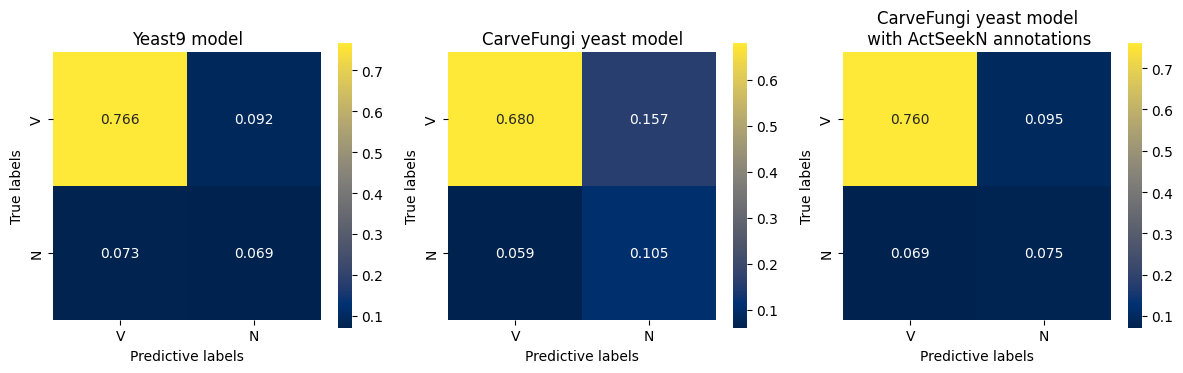

In [25]:
# Create figure with subplots comparing all three models side-by-side
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

# Plot confusion matrices for each model
plot_cm(axes[1], cm_model, "CarveFungi yeast model")
plot_cm(axes[2], cm_model_actseek, "CarveFungi yeast model\n with ActSeekN annotations")
plot_cm(axes[0], cm_model_yeast, "Yeast9 model")
plt.tight_layout()  # Adjust spacing between subplots


# Save the figure as SVG (vector format) for publication qualityplt.show()  # Display the plot
plt.savefig("Essentiality_prediction.svg", format="svg", dpi=300) 